In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

MODELS_DIR = PROJECT_ROOT / "models"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

SAMPLE_SIZE = 10000
RANDOM_STATE = 42

bundle = joblib.load(MODELS_DIR / "serious_best_model.joblib")
config = json.loads((MODELS_DIR / "serious_feature_config.json").read_text())

model = bundle["model"]
FEATURES = bundle["feature_columns"]
TARGET = bundle["target"]

test = pd.read_parquet(PROCESSED_DATA_DIR / "serious_test.parquet")
sample = test.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)
X_sample = sample[FEATURES]

print(f"Model: {bundle['model_name']}")
print(f"Explaining {len(X_sample):,} sampled test reports")

Model: XGBoost
Explaining 10,000 sampled test reports


In [2]:
labels = {
    "age_years": "Age",
    "age_missing": "Age not reported",
    "sex_F": "Female",
    "sex_M": "Male",
    "sex_Unknown": "Sex not reported",
    "n_drugs": "Number of drugs",
    "n_other_drugs": "Unlisted drugs",
    "n_reactions": "Number of reactions",
    "n_other_reactions": "Unlisted reactions",
}

for name, col in zip(config["ingredients"], config["ingredient_columns"]):
    labels[col] = name.replace("\\", " + ").title()

for name, col in zip(config["reactions"], config["reaction_columns"]):
    labels[col] = f"Reaction: {name}"

assert set(FEATURES) <= set(labels), "Every feature needs a readable name"

In [3]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)
print(f"SHAP matrix: {shap_values.shape}")

SHAP matrix: (10000, 809)


In [4]:
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES)
numeric = ["age_years", "n_drugs", "n_other_drugs", "n_reactions", "n_other_reactions"]

direction = {}
for i, feature in enumerate(FEATURES):
    if feature in numeric:
        direction[feature] = np.nan
        continue

    on = X_sample[feature].to_numpy() == 1
    direction[feature] = shap_values[on, i].mean() if on.any() else np.nan

summary = pd.DataFrame(
    {
        "feature": [labels[f] for f in FEATURES],
        "importance": importance.values,
        "effect_when_present": pd.Series(direction)[FEATURES].values,
    },
    index=FEATURES,
)
summary = summary.sort_values("importance", ascending=False)

summary["pushes_towards"] = np.select(
    [summary["effect_when_present"] > 0, summary["effect_when_present"] < 0],
    ["serious", "non-serious"],
    default="depends on value",
)

display(summary.head(20)[["feature", "importance", "pushes_towards"]].round(3))

,feature,importance,pushes_towards
n_other_reactions,Unlisted reactions,0.808,depends on value
n_drugs,Number of drugs,0.370,depends on value
ing_DUPILUMAB,Dupilumab,0.324,non-serious
age_years,Age,0.222,depends on value
n_reactions,Number of reactions,0.112,depends on value
rx_Pneumonia,Reaction: Pneumonia,0.109,serious
ing_TIRZEPATIDE,Tirzepatide,0.074,non-serious
rx_Product_dose_omission_issue,Reaction: Product dose omission issue,0.068,non-serious
rx_No_adverse_event,Reaction: No adverse event,0.065,non-serious
sex_M,Male,0.061,serious


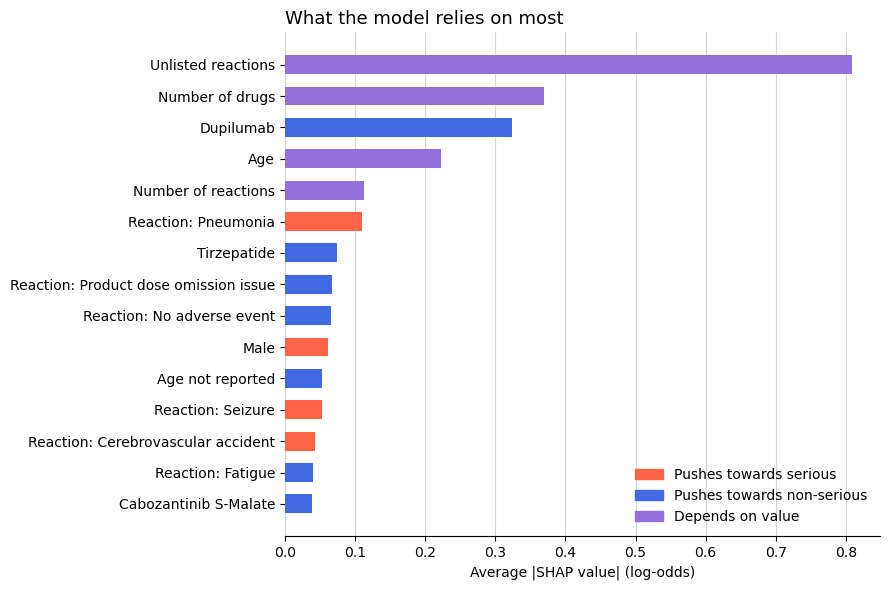

In [5]:
top = summary.head(15).iloc[::-1]

colors = top["pushes_towards"].map({
    "serious": "tomato",
    "non-serious": "royalblue",
    "depends on value": "mediumpurple"
})

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top["feature"],
    top["importance"],
    height=0.6,
    color=colors
)

ax.set_xlabel("Average |SHAP value| (log-odds)")
ax.set_title("What the model relies on most", loc="left", fontsize=13)

ax.grid(axis="x", color="lightgrey", linewidth=0.8)
ax.set_axisbelow(True)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

handles = [
    plt.Rectangle((0, 0), 1, 1, color="tomato"),
    plt.Rectangle((0, 0), 1, 1, color="royalblue"),
    plt.Rectangle((0, 0), 1, 1, color="mediumpurple")
]

ax.legend(
    handles,
    [
        "Pushes towards serious",
        "Pushes towards non-serious",
        "Depends on value"
    ],
    loc="lower right",
    frameon=False
)

plt.tight_layout()
plt.show()

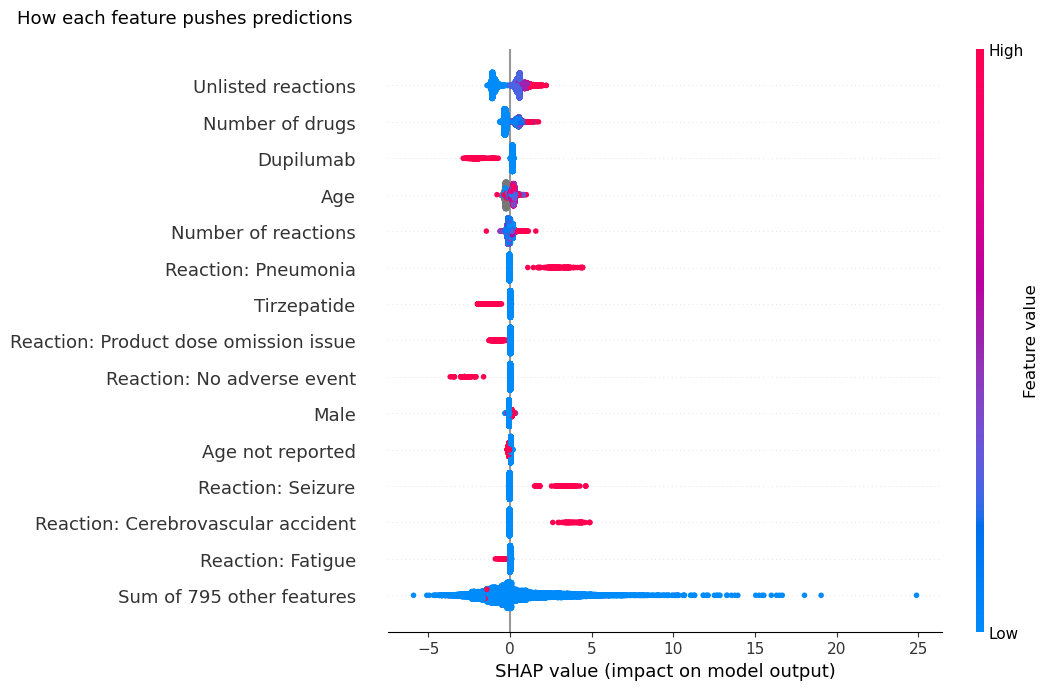

In [6]:
explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(X_sample), explainer.expected_value),
    data=X_sample.to_numpy(dtype=float),
    feature_names=[labels[f] for f in FEATURES],
)

shap.plots.beeswarm(explanation, max_display=15, show=False, plot_size=(11, 7))
plt.gcf().suptitle("How each feature pushes predictions", x=0.02, ha="left", fontsize=13)

plt.tight_layout()
plt.show()

In [7]:
probabilities = model.predict_proba(X_sample)[:, 1]

examples = [
    ("Most confidently serious", int(np.argmax(probabilities))),
    ("Most confidently non-serious", int(np.argmin(probabilities))),
    ("Borderline case", int(np.argmin(np.abs(probabilities - 0.5)))),
]

for title, position in examples:
    row = sample.iloc[position]
    x = row[FEATURES].to_frame().T.astype(float)
    event = x.iloc[0]

    probability = float(model.predict_proba(x)[0, 1])
    values = pd.Series(explainer.shap_values(x)[0], index=FEATURES)

    present = [
        f for f in FEATURES
        if (f in numeric and event[f] > 0) or (f not in numeric and event[f] == 1)
    ]
    present = [f for f in present if not (f == "age_years" and pd.isna(event[f]))]

    chosen = values[present]
    chosen = chosen[chosen.abs() >= 0.02]
    chosen = chosen.reindex(chosen.abs().sort_values(ascending=False).index).head(5)

    predicted_label = "Serious" if probability >= 0.5 else "Non-serious"
    actual_label = "Serious" if row[TARGET] == 1 else "Non-serious"

    print(f"===== {title} =====")
    print(f"Predicted: {predicted_label} ({probability * 100:.1f}% serious)  |  actual: {actual_label}")

    for f, v in chosen.items():
        value_text = "" if f not in numeric else f" = {event[f]:.0f}"
        strength = "strongly " if abs(v) >= 0.5 else "" if abs(v) >= 0.15 else "slightly "
        direction = "raised" if v > 0 else "lowered"
        print(f"  - {labels[f]}{value_text} {strength}{direction} the chance of a serious outcome")

    print()

===== Most confidently serious =====
Predicted: Serious (100.0% serious)  |  actual: Serious
  - Reaction: Myelosuppression strongly raised the chance of a serious outcome
  - Reaction: Acute kidney injury strongly raised the chance of a serious outcome
  - Reaction: Sepsis strongly raised the chance of a serious outcome
  - Reaction: Pancytopenia strongly raised the chance of a serious outcome
  - Reaction: Renal failure strongly raised the chance of a serious outcome

===== Most confidently non-serious =====
Predicted: Non-serious (0.1% serious)  |  actual: Non-serious
  - Reaction: No adverse event strongly lowered the chance of a serious outcome
  - Reaction: Drug dose omission by device strongly lowered the chance of a serious outcome
  - Reaction: Device delivery system issue strongly lowered the chance of a serious outcome
  - Albuterol Sulfate strongly lowered the chance of a serious outcome
  - Reaction: Device malfunction lowered the chance of a serious outcome

===== Borderl

In [8]:
raw_output = model.predict(X_sample, output_margin=True)
shap_total = explainer.expected_value + shap_values.sum(axis=1)

assert np.allclose(raw_output, shap_total, atol=1e-3), "SHAP values must add up to the prediction"
print("All sanity checks passed.")

summary.round(5).to_csv(MODELS_DIR / "serious_shap_importance.csv")
print("Saved models/serious_shap_importance.csv")

All sanity checks passed.
Saved models/serious_shap_importance.csv
